In [1]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter, welch, butter, filtfilt
from scipy.ndimage import gaussian_filter
from numpy import cos, sin
import joblib

In [2]:
def def_parametros():
    parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    return parametros

In [3]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [4]:
def parametros_adicionais(df):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    df['Mach2'] = df['Mach']**2

    df['Va2'] = df['Va']**2

    S = 19.3

    df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
    df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
    df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
    df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
    df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
    df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))

    df['Hdot_W_V_dlt'] = (df['NX']*np.cos(np.radians(df['Alfa'])) + df['NZ']*np.sin(np.radians(df['Alfa'])))*df['W']/df['delta'] # (Hdot/V) * (W/delta), em kgf

    df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    df['NZ_W_dlt_sqr'] = df['NZ_W_dlt']**2

    # Filtro para cortar dados irrelevantes:
    df = df[df['Va_filtered'] > 90]
    df = df[df['Zp'] > 3000]

    return df

In [5]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
    else:
        files = ['039_2013_VIN_FND']

    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
    parametros = def_parametros()
    all_dfs = []
    for file in files:
        data = loadmat(local + file + '.mat')
        df = pd.DataFrame(data['DADOS'])
        df.columns = parametros
        df['filename'] = file
        all_dfs.append(df)
    df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625), 'faixa_altitude'] = 'A'
        df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200), 'faixa_altitude'] = 'B'
        df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54075), 'faixa_altitude'] = 'C'
        df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100), 'faixa_altitude'] = 'D'

    return df

-13.585768869018555
139.93421232910157


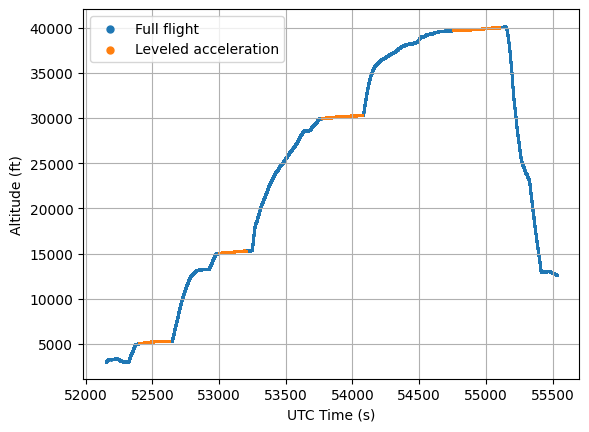

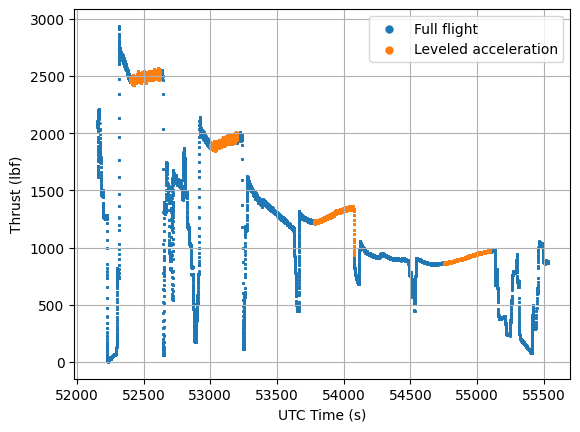

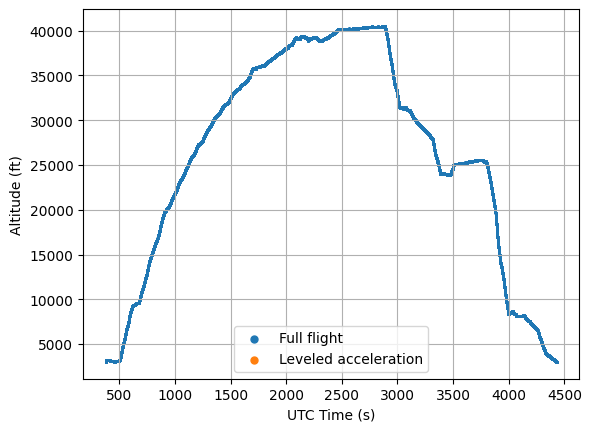

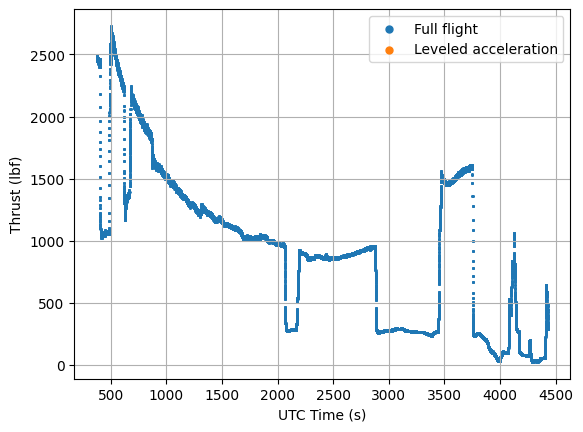

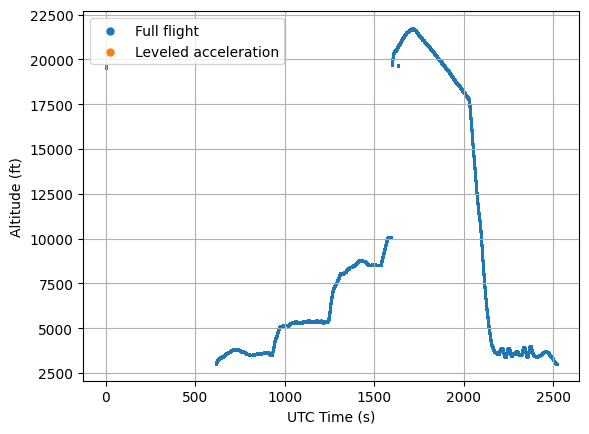

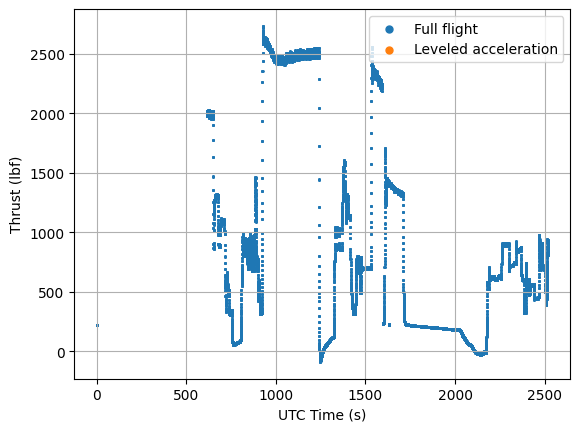

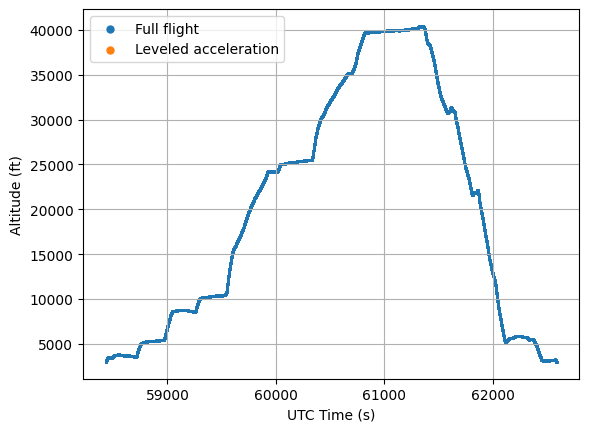

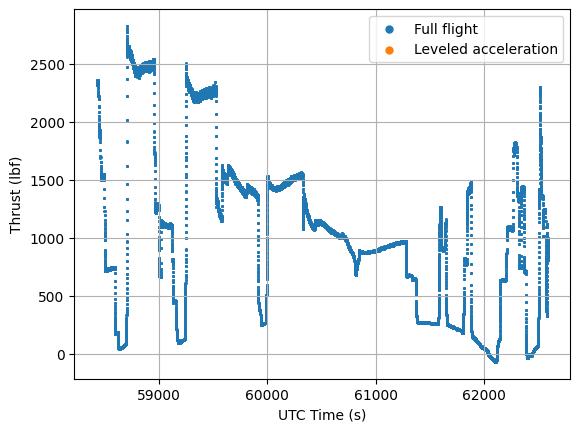

In [6]:
df = make_df('completo')
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

# subset = df[df['type'] == evaluated_set]

print(df['Alfa'].min())
print(df['Alfa'].max())

for filename, grupo in df.groupby('filename'):
    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    mask_leveled_acceleration = (
        ((grupo['TEMPO_SAD'] > 52400) & (grupo['TEMPO_SAD'] < 52625)) +
        ((grupo['TEMPO_SAD'] > 53000) & (grupo['TEMPO_SAD'] < 53200)) +
        ((grupo['TEMPO_SAD'] > 53775) & (grupo['TEMPO_SAD'] < 54075)) +
        ((grupo['TEMPO_SAD'] > 54750) & (grupo['TEMPO_SAD'] < 55100))
    )
    grupo_aceleracao_nivelada = grupo[mask_leveled_acceleration]
    grupo = grupo[mask]


    # plt.title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Zp'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['Zp'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Altitude (ft)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

    plt.scatter(grupo['TEMPO_SAD'], grupo['T'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['T'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Thrust (lbf)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

In [7]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [8]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    # for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
    #     mask = df['type'] == split
    #     df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
    #     df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
    #     # df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])
    #     df.loc[mask, [p+'_scaled' for p in colsy]] = df.loc[mask, colsy].values  # sem escalonamento
    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [9]:
import tensorflow as tf

class PMGModel(keras.Model):
    def __init__(self, main_model, z1_model, ng_index, lambda_mono=1.0, lambda_anchor=0.0, **kwargs):
        super().__init__(**kwargs)
        self.main_model = main_model
        self.z1_model = z1_model
        self.ng_index = ng_index
        self.lambda_mono = lambda_mono
        self.lambda_anchor = lambda_anchor
        self.penalty_tracker = keras.metrics.Mean(name='mono_penalty')
        self.anchor_tracker = keras.metrics.Mean(name='anchor_penalty')
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')

    def call(self, inputs, training=False):
        return self.main_model(inputs, training=training)

    @property
    def metrics(self):
        return super().metrics + [self.penalty_tracker, self.anchor_tracker, self.total_loss_tracker]

    def _physics_terms(self, x1, training):
        """Calcula a penalidade de monotonicidade e reaproveita o mesmo forward
        pass de NN1 (z1) para a penalidade de ancoragem — evita chamar z1_model
        mais de uma vez por passo de treino."""
        precisa_z1 = (self.ng_index is not None and self.lambda_mono != 0) or (self.lambda_anchor != 0)
        if not precisa_z1:
            return tf.constant(0.0), None

        with tf.GradientTape() as tape_phys:
            tape_phys.watch(x1)
            z1 = self.z1_model(x1, training=training)

        if self.ng_index is not None and self.lambda_mono != 0:
            dz1_dx1 = tape_phys.gradient(z1, x1)
            dz1_dng = dz1_dx1[:, self.ng_index]
            mono_penalty = tf.reduce_mean(tf.nn.relu(-dz1_dng))
        else:
            mono_penalty = tf.constant(0.0)

        return mono_penalty, z1

    def _anchor_penalty(self, z1, anchor_target, anchor_mask):
        """Penaliza |Z1 - anchor_target|^2, só nos pontos com anchor_mask == 1
        (ex.: 1% dos pontos de treino, ancorados em Tn_dlt)."""
        if self.lambda_anchor == 0 or z1 is None:
            return tf.constant(0.0)
        erro2 = tf.square(z1[:, 0] - anchor_target) * anchor_mask
        n_ativos = tf.reduce_sum(anchor_mask)
        return tf.reduce_sum(erro2) / (n_ativos + 1e-8)

    def train_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask = x
        with tf.GradientTape() as tape:
            mono_penalty, z1 = self._physics_terms(x1, training=True)
            anchor_penalty = self._anchor_penalty(z1, anchor_target, anchor_mask)
            y_pred = self.main_model([x1, x2], training=True)
            data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
            total_loss = data_loss + self.lambda_mono * mono_penalty + self.lambda_anchor * anchor_penalty

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

        self.penalty_tracker.update_state(mono_penalty)
        self.anchor_tracker.update_state(anchor_penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)
            elif metric.name not in ('mono_penalty', 'anchor_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask = x
        y_pred = self.main_model([x1, x2], training=False)
        data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
        mono_penalty, z1 = self._physics_terms(x1, training=False)
        anchor_penalty = self._anchor_penalty(z1, anchor_target, anchor_mask)
        total_loss = data_loss + self.lambda_mono * mono_penalty + self.lambda_anchor * anchor_penalty

        self.penalty_tracker.update_state(mono_penalty)
        self.anchor_tracker.update_state(anchor_penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)
            elif metric.name not in ('mono_penalty', 'anchor_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

In [10]:
def build_model(features1, features2, architecture={}, hyperparameters={}):
    neurons          = architecture.get('neurons', 32)
    n_hidden         = architecture.get('camadas_ocultas', 2)
    activation       = architecture.get('activation', 'relu')
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters.get('optimizer', 'adam')
    learning_rate    = hyperparameters.get('learning_rate', 0.001)
    epochs           = hyperparameters.get('epochs', 100)
    batch_size       = hyperparameters.get('batch_size', 32)
    patience         = hyperparameters.get('patience', 3)

    def build_subnetwork(input_tensor, name_prefix):
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, activation='softplus', name=f'{name_prefix}_output')(x)
        return z

    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    z1 = build_subnetwork(input_x1, name_prefix='NN1')
    z2 = build_subnetwork(input_x2, name_prefix='NN2')

    output = layers.Subtract(name='Saida_Y')([z1, z2])

    functional_model = Model(inputs=[input_x1, input_x2], outputs=output)
    z1_model = Model(inputs=input_x1, outputs=z1, name='Z1_extractor')

    mono_feature = hyperparameters.get('mono_feature', 'N1_over_sqrt_theta')
    ng_index     = features1.index(mono_feature) if mono_feature in features1 else None
    lambda_mono  = hyperparameters.get('lambda_mono', 1.0)
    lambda_anchor = hyperparameters.get('lambda_anchor', 0.0)   # <-- NOVO

    model = PMGModel(
        main_model=functional_model,
        z1_model=z1_model,
        ng_index=ng_index,
        lambda_mono=lambda_mono,
        lambda_anchor=lambda_anchor,   # <-- NOVO
    )

    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model

In [11]:
def train_model(df, features1, features2, targets, model, hyperparameters, scaler_y):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]
    targets_scaled = [item + '_scaled' for item in targets]

    train_mask = df['type'] == 'train'
    val_mask = df['type'] == 'val'

    X1_train, X1_val = np.array(df.loc[train_mask, features1_scaled]).astype(np.float32), np.array(df.loc[val_mask, features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[train_mask, features2_scaled]).astype(np.float32), np.array(df.loc[val_mask, features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[train_mask, targets_scaled]).astype(np.float32), np.array(df.loc[val_mask, targets_scaled]).astype(np.float32)

    # --- Ancoragem de Z1 em Tn_dlt, numa fração pequena dos pontos ---
    anchor_feature  = hyperparameters.get('anchor_feature', 'Tn_dlt')
    anchor_fraction = hyperparameters.get('anchor_fraction', 0.01)   # 1% por padrão

    if anchor_feature not in df.columns:
        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592

    # scaler_y foi ajustado em Hdot_W_V_dlt (mesma unidade física de Tn_dlt),
    # então dá pra reaproveitá-lo pra levar Tn_dlt pro espaço escalonado de Z1.
    anchor_scaled_full = scaler_y.transform(df[[anchor_feature]].values)[:, 0].astype(np.float32)

    def _build_anchor_mask(mask_split, fraction, seed):
        n = int(mask_split.sum())
        mask_arr = np.zeros(n, dtype=np.float32)
        n_ativos = max(1, int(round(fraction * n))) if fraction > 0 else 0
        if n_ativos > 0:
            rng = np.random.RandomState(seed)
            idx_ativos = rng.choice(n, size=n_ativos, replace=False)
            mask_arr[idx_ativos] = 1.0
        return mask_arr

    anchor_target_train = anchor_scaled_full[train_mask.values]
    anchor_mask_train = _build_anchor_mask(train_mask, anchor_fraction, seed=0)

    anchor_target_val = anchor_scaled_full[val_mask.values]
    anchor_mask_val = _build_anchor_mask(val_mask, anchor_fraction, seed=1)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo...")
    training_history = model.fit(
        [X1_train, X2_train, anchor_target_train, anchor_mask_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val, anchor_target_val, anchor_mask_val], Y_val),
        verbose=0
    )

    joblib.dump(training_history.history, './trainHistoryDict.pkl')

    trained_model = model.main_model if isinstance(model, PMGModel) else model
    trained_model.save('./model.keras')

    return trained_model, training_history

In [12]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets, mode):
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    if mode == 'train':
        model = build_model(features1, features2, architecture, hyperparameters)
        model, training_history = train_model(df, features1, features2, targets, model, hyperparameters, scaler_y)  # <-- scaler_y adicionado
    elif mode == 'read':
        print('Carregando o modelo...')
        model, training_history = keras.models.load_model('./model.keras'), joblib.load('./trainHistoryDict.pkl')
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [13]:
def evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set='test'):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]

    # Previsão sobre todo o dataframe
    X_all = [
        np.array(df[features1_scaled]).astype(np.float32),
        np.array(df[features2_scaled]).astype(np.float32)
    ]

    pred_scaled_all = model.predict(X_all)
    pred_all = scaler_y.inverse_transform(pred_scaled_all)
    # pred_all = pred_scaled_all

    for i, item in enumerate(targets):
        df[item + '_pred'] = pred_all[:, i]

    # Monta results somente com o subconjunto avaliado
    mask = df['type'] == evaluated_set

    pred = pred_all[mask.values]
    real = np.array(df.loc[mask, targets]).astype(np.float32)

    erro = abs(pred - real)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)


    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }

    return results, df

In [14]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 32,
            'camadas_ocultas': 3,
            'activation': 'relu',
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 200,
            'batch_size': 64,
            'patience': 4,
            'lambda_mono': 1.0,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
        },
        # architecture={
        #     'neurons': 5,
        #     'camadas_ocultas': 1,
        #     'activation': 'relu',
        #     'dropout': 0
        # },
        # hyperparameters={
        #     'optimizer': 'adam',
        #     'learning_rate': 0.01,
        #     'epochs': 2,
        #     'batch_size': 64,
        #     'patience': 2
        # },
        evaluated_set='test',
        mode='train'
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets,
        mode=mode
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results, df = evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        # figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}'], dot_size, label=f'{item} Real')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}_pred'], dot_size, label=f'{item} Predito')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Erro médio (|pred-real|): {results["avg_error"][i]:.2f}')
        axs[2*i+1].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()

    plt.savefig(f'figures/{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

In [15]:
def mase_pointwise(y_pred, y_true):
    """
    Erro ponto a ponto normalizado pelo naive forecast (passo anterior de y_true).
    Retorna array com mesma forma de y_true.
    """
    naive_mae = np.mean(np.abs(np.diff(y_true)))  # denominador escalar
    if naive_mae == 0:
        return np.full(len(y_true), np.nan)
    return np.abs(y_pred - y_true) / naive_mae

Treinando modelo com 3 camadas, 20 neurônios, lambda_mono = 0.0, lambda_anchor = 1.0, anchor_fraction = 1.0...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 642us/step


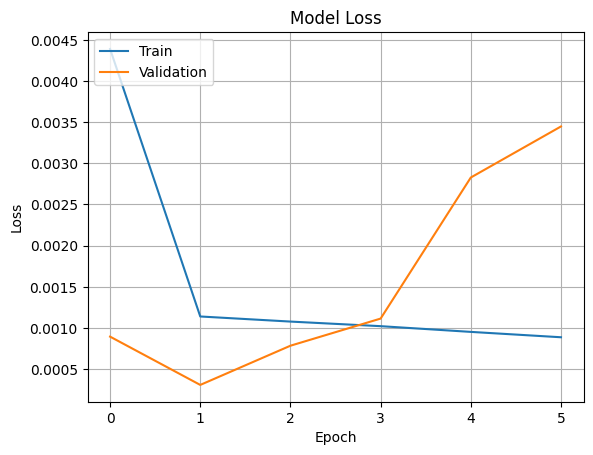

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


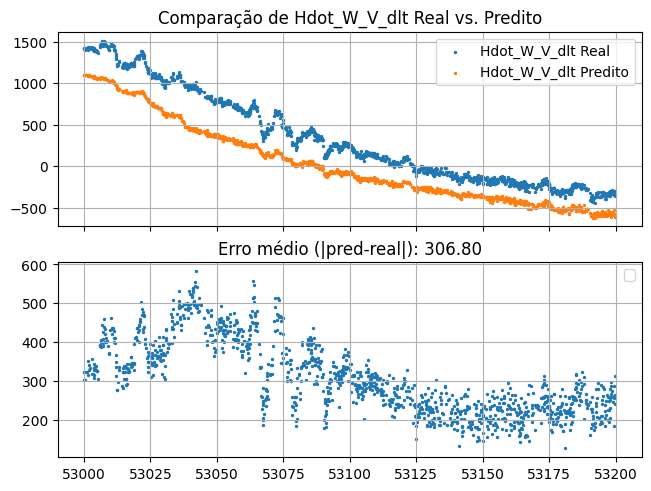

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 629us/step
Treinando modelo com 3 camadas, 20 neurônios, lambda_mono = 0.0, lambda_anchor = 2, anchor_fraction = 1.0...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 549us/step


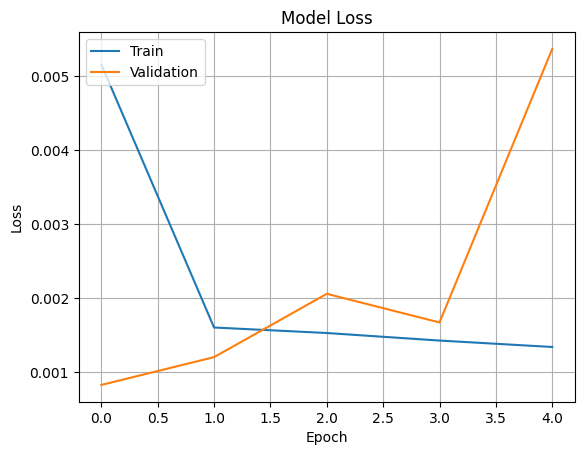

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


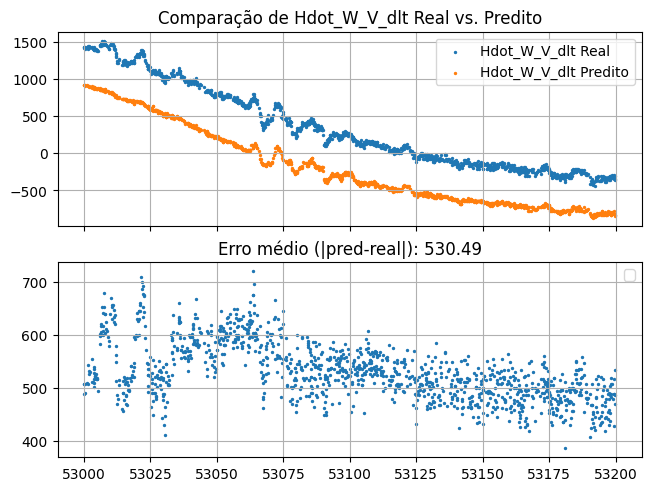

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 610us/step
Treinando modelo com 3 camadas, 20 neurônios, lambda_mono = 0.0, lambda_anchor = 8, anchor_fraction = 1.0...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 558us/step


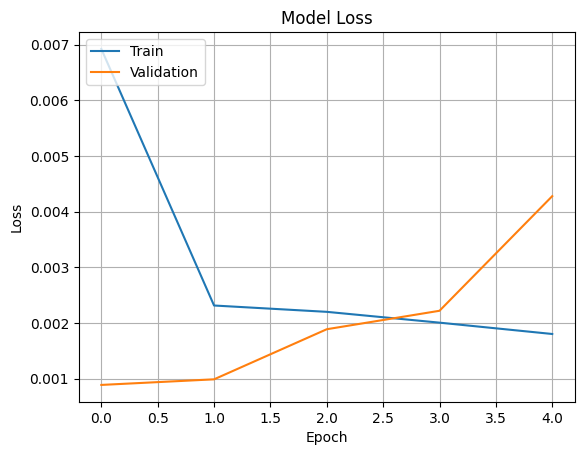

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


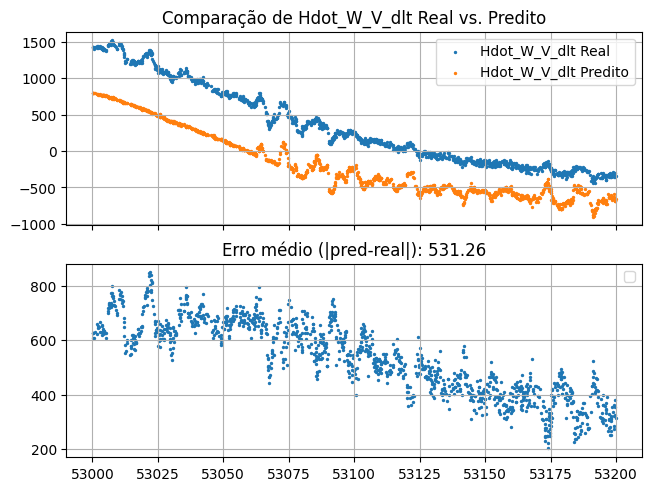

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 592us/step
Treinando modelo com 3 camadas, 20 neurônios, lambda_mono = 0.0, lambda_anchor = 100.0, anchor_fraction = 1.0...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 564us/step


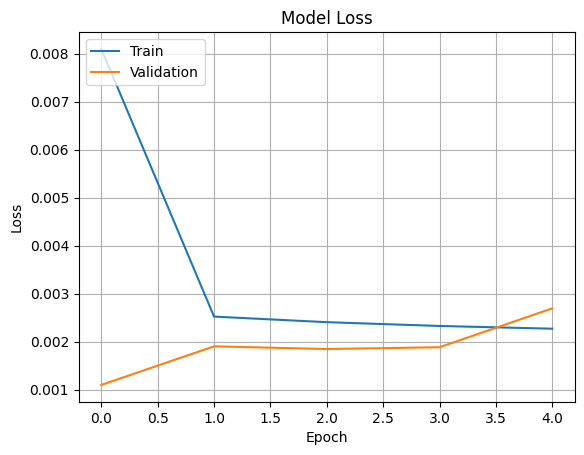

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


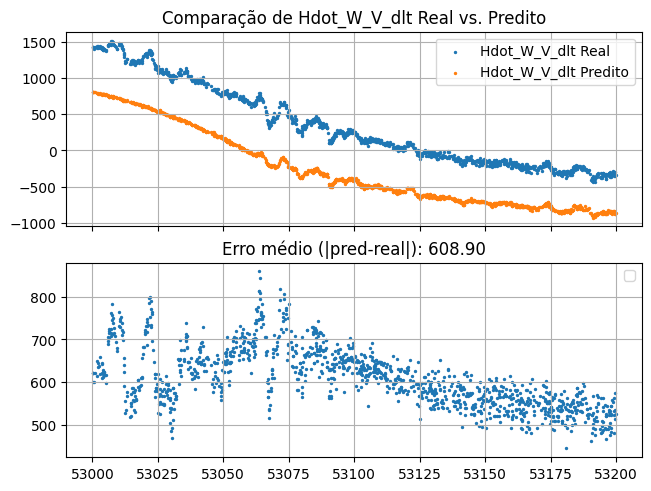

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 577us/step
Treinando modelo com 3 camadas, 20 neurônios, lambda_mono = 0.0, lambda_anchor = 1000.0, anchor_fraction = 1.0...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 563us/step


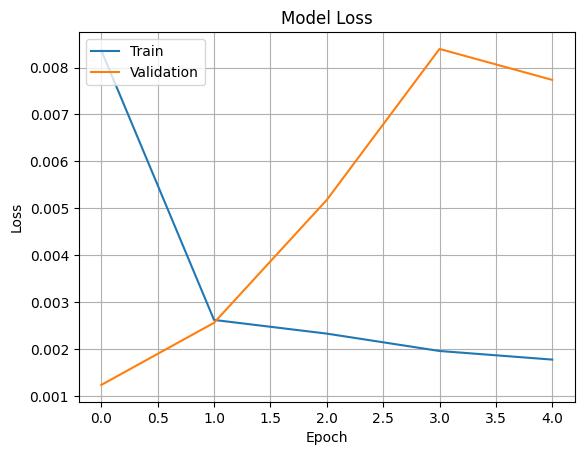

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


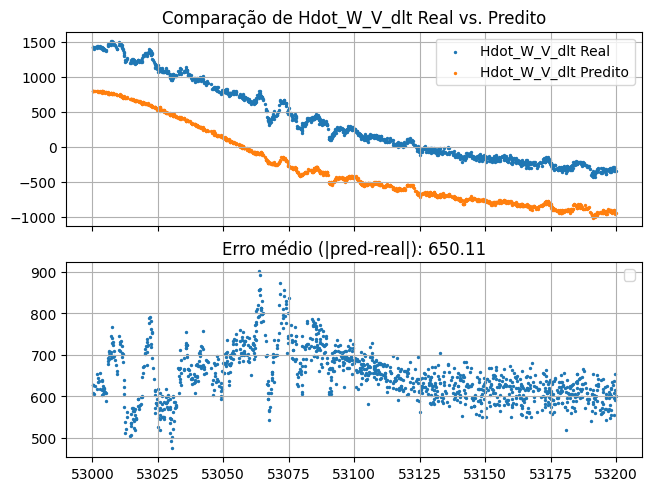

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 584us/step
Salvo resumo com 5 linhas em test4/metricas_diagnostico.csv
PDF salvo em test4/relatorio_diagnostico_grid_search.pdf com 1 páginas


In [29]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
from reportlab.lib.styles import getSampleStyleSheet

camadas = [2, 3, 4, 5, 6]
neuronios = [10, 20, 50]
# lambda_mono_values = [0, 0.05, 0.1, 0.12, 0.15, 0.2, 0.3, 0.5, 1.0]
lambda_mono_values = [0]
# lambda_anchor_values = [0.01, 0.1, 0.15, 0.2, 0.3, 0.5, 0.8, 1.0]   # peso da penalidade Z1 vs Tn_dlt (0 = desligado, comportamento antigo)
lambda_anchor_values = [0.1, 0.25, 0.5, 0.8, 1.0]   # peso da penalidade Z1 vs Tn_dlt (0 = desligado, comportamento antigo)
anchor_fraction_values = [0.01, 0.025, 0.05, 0.1]  # fração dos pontos de treino usada como âncora

camadas = [3]              # <-- descomente estas 3 linhas para um teste rápido
neuronios = [20]            #     com 1 combinação só, antes de rodar o grid completo
lambda_mono_values = [0.0]
lambda_anchor_values = [1.0, 2, 8, 1e2, 1e3]   # peso da penalidade Z1 vs Tn_dlt (0 = desligado, comportamento antigo)
anchor_fraction_values = [1.0]  # fração dos pontos de treino usada como âncora


evaluated_set = 'test'
dot_size = 1
time_intervals = {
    '039_2013_VIN_FND': (5e4, 7e4),
    '040_2013_ASO_VTO': (0, 5e4),
    '041_2013_GEO_AIR': (0, 1e5),
    '042_2013_VAU_FTR': (0, 8e4),
}

# folder = 'dZ1dNGgeq0'
# folder = 'dZ1dtgeq0'
folder = 'test4'
# folder = 'gridSearch_anchoring'

OUT_DIR = f'{folder}/figures/grid_search_diagnostico'
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(folder, exist_ok=True)

metricas = []
pdf_story = []
styles = getSampleStyleSheet()

MAX_LARGURA_CM = 18.0   # área útil de uma página A4 retrato (menos margens)
MAX_ALTURA_CM = 24.0    # idem, descontando margens e o título da página

for camada in camadas:
    for neuronio in neuronios:
        for lambda_mono in lambda_mono_values:
            for lambda_anchor in lambda_anchor_values:
                for anchor_fraction in anchor_fraction_values:
                    print(f"Treinando modelo com {camada} camadas, {neuronio} neurônios, lambda_mono = {lambda_mono}, lambda_anchor = {lambda_anchor}, anchor_fraction = {anchor_fraction}...")
                    df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
                        tipo_dados='',
                        features1=['Mach', 'N1_over_sqrt_theta'],
                        features2=['Mach2', 'NZ_W_dlt_sqr'],
                        targets=['Hdot_W_V_dlt'],
                        mode='train',
                        architecture={
                            'neurons': neuronio,
                            'camadas_ocultas': camada,
                            'activation': 'relu',
                            'dropout': 0,
                        },
                        hyperparameters={
                            'optimizer': 'adam',
                            'learning_rate': 0.001,
                            'epochs': 100,
                            'batch_size': 32,
                            'patience': 4,
                            'lambda_mono': lambda_mono,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
                            'lambda_anchor': lambda_anchor,      # peso da penalidade Z1 vs Tn_dlt (0 = desligado, comportamento antigo)
                            'anchor_fraction': anchor_fraction,   # fração dos pontos de treino usada como âncora

                        },
                    )

                    extractor = keras.Model(
                        inputs=model.inputs,
                        outputs=[
                            model.get_layer('NN1_output').output,  # Z1
                            model.get_layer('NN2_output').output,  # Z2
                            model.output                           # Y (Z1 - Z2)
                        ]
                    )

                    features1 = ['Mach', 'N1_over_sqrt_theta']
                    features2 = ['Mach2', 'NZ_W_dlt_sqr']

                    features1_scaled = [f + '_scaled' for f in features1]
                    features2_scaled = [f + '_scaled' for f in features2]

                    X1_all = np.array(df[features1_scaled]).astype(np.float32)
                    X2_all = np.array(df[features2_scaled]).astype(np.float32)

                    z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

                    # Adiciona ao DataFrame (ainda em escala normalizada)
                    df['Z1_scaled'] = z1_vals.flatten()
                    df['Z2_scaled'] = z2_vals.flatten()

                    df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
                    df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()
                    df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()

                    df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
                    df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

                    subset = df[df['type'] == evaluated_set]
                    combo_dir = os.path.join(OUT_DIR, f'c{camada}_n{neuronio}_l{lambda_mono}_la{lambda_anchor}_af{anchor_fraction}')
                    os.makedirs(combo_dir, exist_ok=True)

                    # só os voos que de fato aparecem no conjunto de teste desta combinação
                    voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]
                    n_voos = len(voos_presentes)
                    n_metricas = 4  # pred_vs_real, erro_abs, Z1_vs_Tn, Z2_vs_D

                    altura_total_in = 5.5 * n_metricas
                    largura_total_in = altura_total_in * (MAX_LARGURA_CM / MAX_ALTURA_CM)
                    fig_pdf, axs_pdf = plt.subplots(n_metricas, n_voos, figsize=(largura_total_in, altura_total_in), squeeze=False)

                    for col_idx, filename in enumerate(voos_presentes):
                        grupo = subset[subset['filename'] == filename]
                        t0, t = time_intervals[filename]
                        mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
                        grupo = grupo[mask].copy()

                        # erro_mase = mase_pointwise(grupo['Z1'].values, grupo['Tn_dlt'].values)

                        k = min(min(grupo['Z1']), min(grupo['Z2']))
                        grupo['Z1'], grupo['Z2'] = (
                            grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
                            grupo['Z2'] - k
                        )

                        erro_abs_medio = abs(grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean()
                        erro_rel_D = ((grupo['D_dlt'] - grupo['Z2']) * 100 / grupo['D_dlt']).mean()

                        erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
                        erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
                        erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

                        metricas.append({
                            'camadas': camada, 'neuronios': neuronio, 'lambda_mono': lambda_mono,
                            'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
                            'filename': filename,
                            'erroH': erroH, 'erroD': erroD, 'erroT': erroT
                        })

                        base = os.path.join(combo_dir, filename)

                        # --- linha 0: pred vs real ---
                        plt.figure(figsize=(10, 4))
                        plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
                        plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
                        plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
                        plt.savefig(f'{base}_pred_vs_real.png', dpi=120); plt.close()

                        ax = axs_pdf[0, col_idx]
                        ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size*3, label='Hdot_W_V_dlt_pred')
                        ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size*3, label='Hdot_W_V_dlt')
                        ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)
                        ax.set_title(filename, fontsize=11, fontweight='bold')

                        # --- linha 1: erro absoluto ---
                        plt.figure(figsize=(10, 4))
                        plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
                                    label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
                        plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
                        plt.savefig(f'{base}_erro_abs.png', dpi=120); plt.close()

                        ax = axs_pdf[1, col_idx]
                        ax.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size*3,
                                label='|erro|')
                        ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

                        # --- linha 2: Z1 vs Tn_dlt ---
                        plt.figure(figsize=(10, 4))
                        plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
                        plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
                        plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
                        plt.xlabel('DAQ Time (s)'); plt.grid()
                        plt.savefig(f'{base}_Z1_vs_Tn.png', dpi=120); plt.close()

                        ax = axs_pdf[2, col_idx]
                        ax.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size*3, label='Z1')
                        ax.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size*3, label=r'Tcos$\alpha$/$\delta$')
                        ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

                        # --- linha 3: Z2 vs D_dlt ---
                        plt.figure(figsize=(10, 4))
                        plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
                        plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
                        plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
                        plt.xlabel('DAQ Time (s)'); plt.grid()
                        plt.savefig(f'{base}_Z2_vs_D.png', dpi=120); plt.close()

                        ax = axs_pdf[3, col_idx]
                        ax.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size*3, label='Z2')
                        ax.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size*3, label=r'D/$\delta$')
                        ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

                    # rótulos das linhas (métricas) só na primeira coluna, pra não repetir
                    row_labels = ['Pred vs Real', '|Erro|', 'Z1 vs Tn', 'Z2 vs D']
                    for row_idx, label in enumerate(row_labels):
                        axs_pdf[row_idx, 0].set_ylabel(label, fontsize=11, fontweight='bold')

                    fig_pdf.suptitle(f'{camada} camada(s) | {neuronio} neurônios | lambda_mono = {lambda_mono} | lambda_anchor = {lambda_anchor} | anchor_fraction = {anchor_fraction}', fontsize=16)
                    fig_pdf.tight_layout(rect=[0, 0, 1, 0.97])
                    page_img_path = os.path.join(combo_dir, 'pagina_pdf.png')
                    fig_pdf.savefig(page_img_path, dpi=110)
                    plt.close(fig_pdf)

                    pdf_story.append(Paragraph(
                        f'Camadas: {camada} | Neurônios: {neuronio} | lambda_mono: {lambda_mono} | lambda_anchor: {lambda_anchor} | anchor_fraction: {anchor_fraction}', styles['Heading3']
                    ))

                    img_w_px, img_h_px = PILImage.open(page_img_path).size
                    razao = img_w_px / img_h_px
                    largura_cm = MAX_LARGURA_CM
                    altura_cm = largura_cm / razao
                    if altura_cm > MAX_ALTURA_CM:
                        altura_cm = MAX_ALTURA_CM
                        largura_cm = altura_cm * razao

                    pdf_story.append(Image(page_img_path, width=largura_cm * cm, height=altura_cm * cm))
                    pdf_story.append(PageBreak())

                    del df, model, training_history, results
                    gc.collect()

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(f'{folder}/metricas_diagnostico.csv', index=False)
print(f"Salvo resumo com {len(df_metricas)} linhas em {folder}/metricas_diagnostico.csv")

doc = SimpleDocTemplate(
    f'{folder}/relatorio_diagnostico_grid_search.pdf',
    pagesize=A4,
    topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=1.5 * cm, rightMargin=1.5 * cm
)
doc.build(pdf_story)
print(f"PDF salvo em {folder}/relatorio_diagnostico_grid_search.pdf com {len(camadas)*len(neuronios)*len(lambda_mono_values)} páginas")

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 685us/step


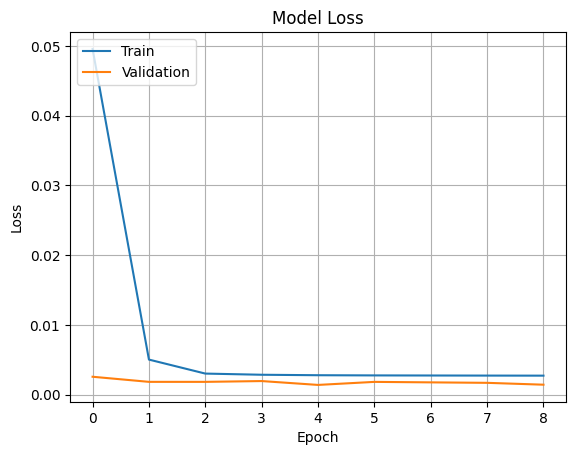

C:\Users\ymarc\AppData\Local\Temp\ipykernel_11144\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


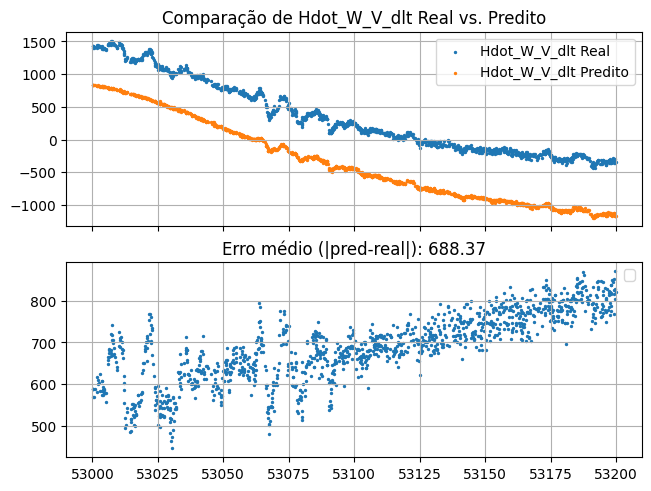

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 865us/step


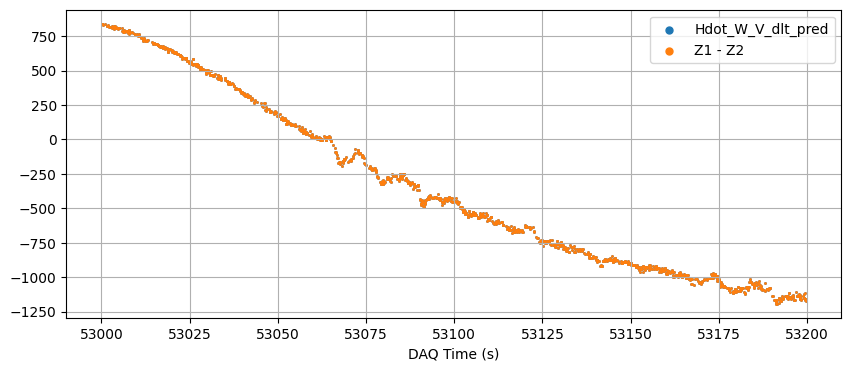

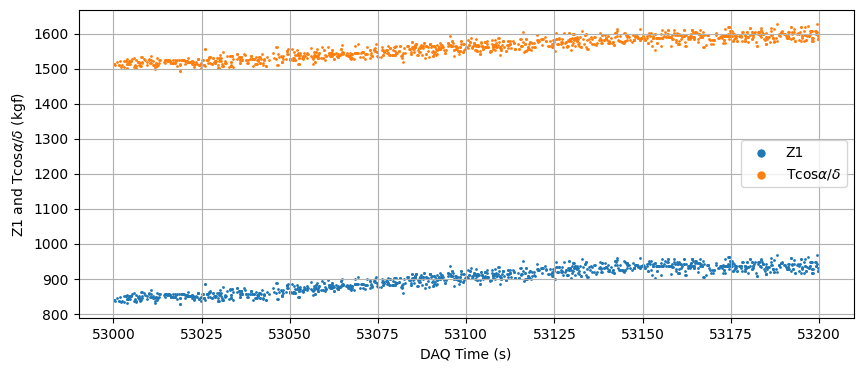

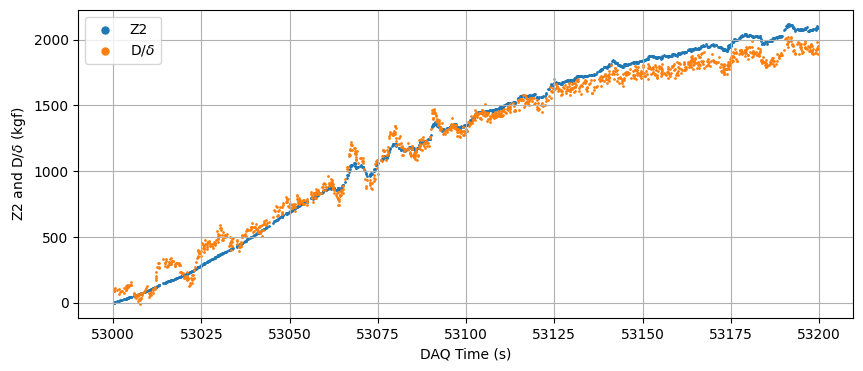

In [30]:
neuronio = 20
camada = 3
lambda_mono = 0.0
lambda_anchor = 1e3
anchor_fraction = 1

df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='',
    features1=['Mach', 'N1_over_sqrt_theta'],
    features2=['Mach2', 'NZ_W_dlt_sqr'],
    targets=['Hdot_W_V_dlt'],
    mode='train',
    architecture={
        'neurons': neuronio,
        'camadas_ocultas': camada,
        'activation': 'relu',
        'dropout': 0,
    },
    hyperparameters={
        'optimizer': 'adam',
        'learning_rate': 0.0001,
        'epochs': 100,
        'batch_size': 32,
        'patience': 4,
        'lambda_mono': lambda_mono,
        'lambda_anchor': lambda_anchor,
        'anchor_fraction': anchor_fraction
    },
)

extractor = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer('NN1_output').output,  # Z1
        model.get_layer('NN2_output').output,  # Z2
        model.output                           # Y (Z1 - Z2)
    ]
)

features1 = ['Mach', 'N1_over_sqrt_theta']
features2 = ['Mach2', 'NZ_W_dlt_sqr']

features1_scaled = [f + '_scaled' for f in features1]
features2_scaled = [f + '_scaled' for f in features2]

X1_all = np.array(df[features1_scaled]).astype(np.float32)
X2_all = np.array(df[features2_scaled]).astype(np.float32)

z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

# Adiciona ao DataFrame (ainda em escala normalizada)
df['Z1_scaled'] = z1_vals.flatten()
df['Z2_scaled'] = z2_vals.flatten()

df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()
df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()

df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

evaluated_set = 'test'

subset = df[df['type'] == evaluated_set]

voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]

metricas = []

for col_idx, filename in enumerate(voos_presentes):
    grupo = subset[subset['filename'] == filename]
    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask].copy()

    k = min(min(grupo['Z1']), min(grupo['Z2']))
    grupo['Z1'], grupo['Z2'] = (
        grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
        grupo['Z2'] - k
    )
    erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
    erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
    erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

    metricas.append({
        'camadas': camada, 'neuronios': neuronio, 'lambda_mono': lambda_mono, 'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
        'filename': filename,
        'erroH': erroH, 'erroD': erroD, 'erroT': erroT
    })

    # base = os.path.join(combo_dir, filename)

    # # --- linha 0: pred vs real ---
    # plt.figure(figsize=(10, 4))
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
    # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
    # plt.plot()

    # # --- linha 1: erro absoluto ---
    # plt.figure(figsize=(10, 4))
    # plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
    #             label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
    # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
    # plt.plot()

    plt.figure(figsize=(10, 4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'], s=dot_size, label='Z1 - Z2')
    plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
    plt.plot()

    # --- linha 2: Z1 vs Tn_dlt ---
    plt.figure(figsize=(10, 4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
    plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
    plt.xlabel('DAQ Time (s)'); plt.grid()
    plt.plot()

    # --- linha 3: Z2 vs D_dlt ---
    plt.figure(figsize=(10, 4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
    plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
    plt.xlabel('DAQ Time (s)'); plt.grid()
    plt.plot()

[]

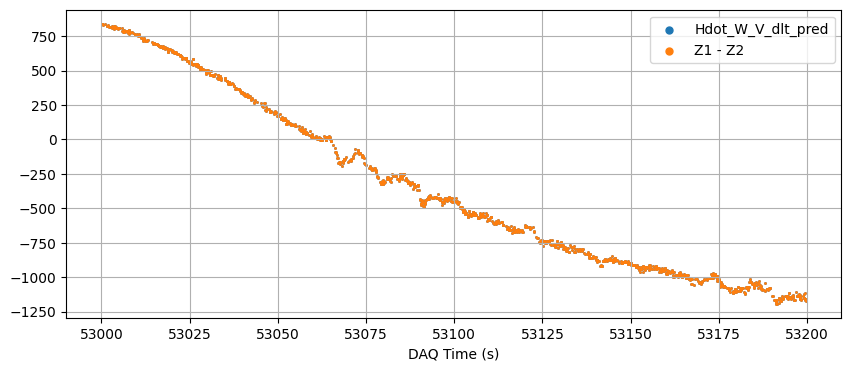

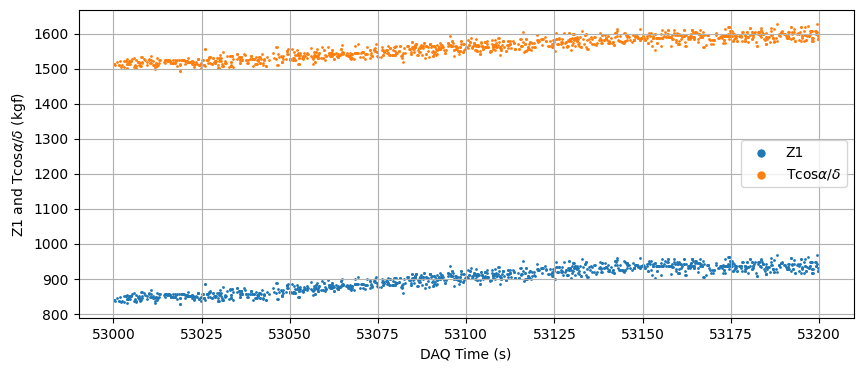

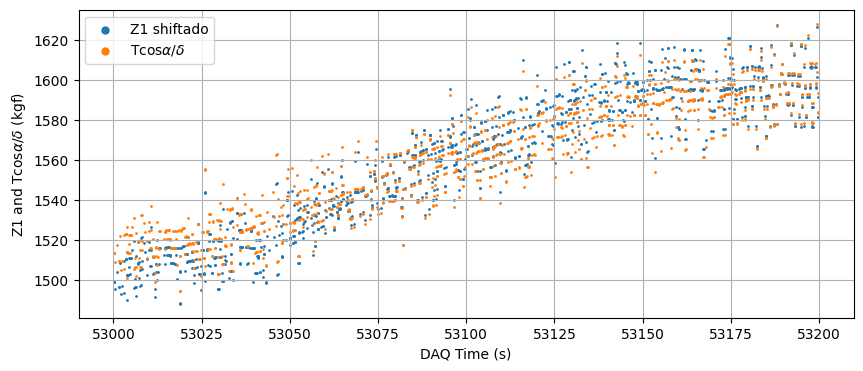

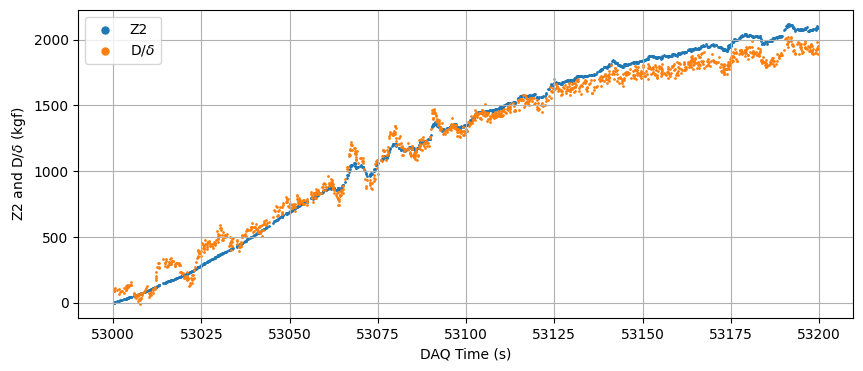

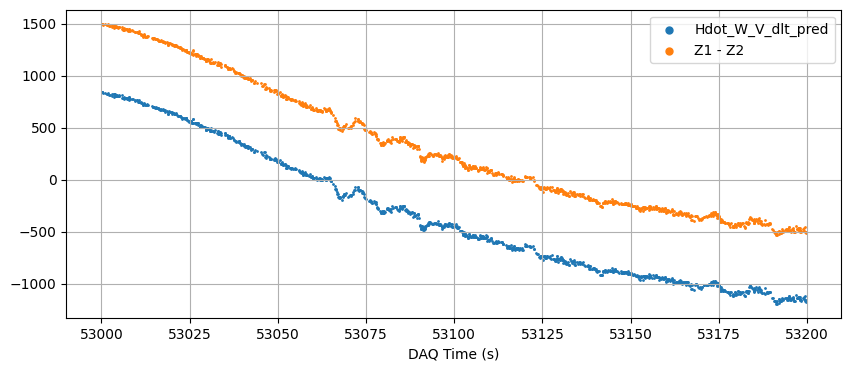

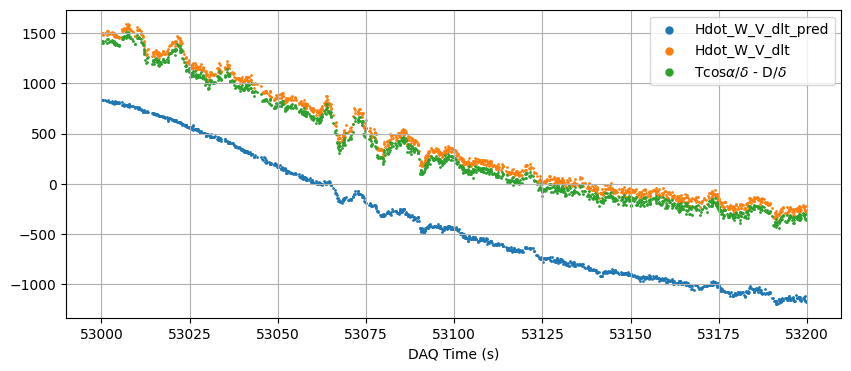

In [40]:
# k = min(min(grupo['Z1']), min(grupo['Z2']))
# grupo['Z1'], grupo['Z2'] = (
#     grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
#     grupo['Z2'] - k
# )
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'], s=dot_size, label='Z1 - Z2')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

# --- linha 2: Z1 vs Tn_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

# --- linha 2: Z1 vs Tn_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] + (grupo['Tn_dlt'] - grupo['Z1']).mean(), s=dot_size, label='Z1 shiftado')
plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

# --- linha 3: Z2 vs D_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] + (grupo['Tn_dlt'] - grupo['Z1']).mean() - grupo['Z2'], s=dot_size, label='Z1 - Z2')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
dy = 80
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'] + dy, s=dot_size, label='Hdot_W_V_dlt')
plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'] - grupo['D_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$ - D/$\delta$')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()


In [ ]:
# =========================================================
# Relatório em PDF do grid search (camadas x neurônios x lambda_mono)
# Lê os resultados salvos em `lista_resultados` (mesma ordem de geração:
# for camada -> for neuronio -> for lambda_mono) e monta um PDF com:
#   - tabela resumo (camadas, neurônios, lambda_mono, erro médio no teste, épocas)
#   - 1 página por combinação, reproduzindo os DOIS gráficos que analyze() já plota:
#     (1) loss de treino/validação e (2) real vs. predito + erro relativo
# =========================================================
import itertools
import os
import matplotlib.pyplot as plt
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

TARGET = 'Hdot_W_V_dlt'   # ajuste aqui se o target do loop de treino mudar
EVALUATED_SET = 'test'

combinacoes = list(itertools.product(camadas, neuronios, lambda_mono_values))

assert len(combinacoes) == len(lista_resultados), (
    f"Número de combinações esperadas ({len(combinacoes)}) difere do número de "
    f"resultados em lista_resultados ({len(lista_resultados)}). Rode novamente a célula "
    "de treino (com o append corrigido) antes de gerar o relatório."
)

OUT_DIR = 'figures/grid_search_report'
os.makedirs(OUT_DIR, exist_ok=True)

styles = getSampleStyleSheet()
title_style = styles['Heading2']
body_style = styles['Normal']

doc = SimpleDocTemplate(
    'relatorio_grid_search.pdf',
    pagesize=A4,
    topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=2 * cm, rightMargin=2 * cm
)
story = []

story.append(Paragraph('Grid Search — camadas x neurônios x lambda_mono', styles['Title']))
story.append(Spacer(1, 12))
story.append(Paragraph(
    f'{len(combinacoes)} combinações treinadas '
    f'({len(camadas)} camadas × {len(neuronios)} neurônios × {len(lambda_mono_values)} lambda_mono). '
    'A tabela abaixo resume cada caso; nas páginas seguintes, cada combinação tem sua própria página '
    'com a curva de loss de treino/validação e a comparação real vs. predito + erro relativo no conjunto de teste.',
    body_style
))
story.append(Spacer(1, 12))

resumo_data = [['#', 'Camadas', 'Neurônios', 'lambda_mono', 'Erro médio teste (%)', 'Épocas treinadas']]
for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    _, _, _, _, _, training_history, results = lista_resultados[idx]
    erro = results['avg_error'][0] if results is not None else float('nan')
    n_epochs = len(training_history.history['loss'])
    resumo_data.append([str(idx + 1), str(camada), str(neuronio), str(lambda_mono), f'{erro:.2f}', str(n_epochs)])

tabela = Table(resumo_data, repeatRows=1)
tabela.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#2c3e50')),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('FONTSIZE', (0, 0), (-1, -1), 8),
    ('GRID', (0, 0), (-1, -1), 0.25, colors.grey),
    ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#f2f2f2')]),
    ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
]))
story.append(tabela)
story.append(PageBreak())

for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    df, _, _, _, _, training_history, results = lista_resultados[idx]
    hist = training_history.history
    mask = df['type'] == EVALUATED_SET

    fig = plt.figure(figsize=(8, 10), constrained_layout=True)
    gs = fig.add_gridspec(3, 1, height_ratios=[1, 1.3, 1])

    ax_loss = fig.add_subplot(gs[0])
    ax_loss.plot(hist['loss'], label='Train')
    ax_loss.plot(hist['val_loss'], label='Validation')
    ax_loss.set_title('Model Loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend(loc='upper right')
    ax_loss.grid(True)

    ax_cmp = fig.add_subplot(gs[1])
    ax_cmp.scatter(df.loc[mask, 'TEMPO_SAD'], df.loc[mask, TARGET], s=2, label=f'{TARGET} Real')
    ax_cmp.scatter(df.loc[mask, 'TEMPO_SAD'], df.loc[mask, f'{TARGET}_pred'], s=2, label=f'{TARGET} Predito')
    ax_cmp.set_title(f'Comparação de {TARGET} Real vs. Predito')
    ax_cmp.legend()
    ax_cmp.grid(True)

    ax_err = fig.add_subplot(gs[2])
    ax_err.scatter(df.loc[mask, 'TEMPO_SAD'], results['rel_error'][:, 0], s=2)
    ax_err.set_title(f'Erro médio: {results["avg_error"][0]:.2f}%')
    ax_err.grid(True)

    fig.suptitle(f'{camada} camada(s), {neuronio} neurônios, λ_mono = {lambda_mono}', fontsize=13)

    img_path = f'{OUT_DIR}/caso_{idx + 1:03d}.png'
    fig.savefig(img_path, dpi=150)
    plt.close(fig)

    story.append(Paragraph(
        f'Caso {idx + 1}/{len(combinacoes)} — Camadas: {camada} | Neurônios: {neuronio} | lambda_mono: {lambda_mono}',
        title_style
    ))
    story.append(Spacer(1, 6))
    story.append(Image(img_path, width=14 * cm, height=17.5 * cm))
    story.append(PageBreak())

doc.build(story)
print(f'Relatório salvo em relatorio_grid_search.pdf ({len(combinacoes)} casos, 1 página de gráficos por caso).')

Relatório salvo em relatorio_grid_search.pdf (24 casos, 1 página de gráficos por caso).


In [ ]:
# =========================================================
# Salvar os resultados do grid search (versão leve e "picklable")
# NÃO fazemos pickle de `lista_resultados` diretamente: cada item carrega um
# modelo Keras inteiro, e isso já quebrou antes (History.model + hook do scikeras
# tentando serializar via get_config()). Em vez disso, extraímos só o que o
# relatório precisa: hiperparâmetros, histórico de loss (dict simples) e os
# resultados de teste (arrays numpy + um recorte pequeno do df).
# =========================================================
import itertools
import os
import pickle

TARGET = 'Hdot_W_V_dlt'   # mesmo target usado no loop de treino
EVALUATED_SET = 'test'

os.makedirs('resultados_grid_search', exist_ok=True)

combinacoes = list(itertools.product(camadas, neuronios, lambda_mono_values))
assert len(combinacoes) == len(lista_resultados), (
    f"Número de combinações esperadas ({len(combinacoes)}) difere do número de "
    f"resultados em lista_resultados ({len(lista_resultados)})."
)

resultados_leves = []
for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    df, _, _, _, model, training_history, results = lista_resultados[idx]
    mask = df['type'] == EVALUATED_SET
    df_test = df.loc[mask, ['TEMPO_SAD', TARGET, f'{TARGET}_pred', 'type']].copy()

    resultados_leves.append({
        'camadas': camada,
        'neuronios': neuronio,
        'lambda_mono': lambda_mono,
        'history': training_history.history,   # dict simples (loss/val_loss), picklable
        'results': results,                    # dict com predicted/real/rel_error/avg_error
        'df_test': df_test,                    # só as colunas usadas no relatório
    })

    # Opcional: salvar o modelo treinado para reuso futuro.
    # Use o formato nativo do Keras, NÃO pickle do objeto `model`:
    # model.save(f'resultados_grid_search/modelo_{idx + 1:03d}.keras')

with open('resultados_grid_search/lista_resultados.pkl', 'wb') as f:
    pickle.dump(resultados_leves, f)

print(f"Salvos {len(resultados_leves)} resultados em resultados_grid_search/lista_resultados.pkl")

Salvos 24 resultados em resultados_grid_search/lista_resultados.pkl


In [36]:
df['Vdot'] = None
df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot'] = savgol_filter(
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Va']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.5144


evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

df['Tn_dlt'] = ( df['T']*cos(np.radians(df['Alfa_filtered']))/df['delta'] ) * 0.453592 # Tração normal, em kgf
df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

df['Z1_dot_trend'] = None
df['Tn_dlt_dot_trend'] = None

df['Z2_dot_trend'] = None
df['D_dlt_dot_trend'] = None

n=501
grau=2
T = 1/32

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    grupo['Z1_dot_trend'] = savgol_filter(
        grupo['Z1'], window_length=n, polyorder=grau, deriv=1, delta=T
    )
    grupo['Tn_dlt_dot_trend'] = savgol_filter(
        grupo['Tn_dlt'], window_length=n, polyorder=grau, deriv=1, delta=T
    )

    # erro_relativo = abs((grupo['Z1_dot_trend'] - grupo['Tn_dlt_dot_trend']) / grupo['Tn_dlt_dot_trend']) * 100

    erro_mase = mase_pointwise(
        grupo['Z1_dot_trend'].values,
        grupo['Tn_dlt_dot_trend'].values
    )

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1_dot_trend'], s=dot_size, label='d(Z1)/dt')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt_dot_trend'], s=dot_size, label=r'd(Tcos$\alpha$/$\delta$)/dt')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ derivatives (kgf/s)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], erro_mase, s=dot_size, label='Z1')
    plt.title(f'MASE médio: {np.nanmean(erro_mase):.4f}')
    plt.ylabel('MASE (adimensional)')
    # plt.ylim(0, 5)  # ajuste conforme necessário
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()
for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    grupo['Z2_dot_trend'] = savgol_filter(
        grupo['Z2'], window_length=n, polyorder=grau, deriv=1, delta=T
    )
    grupo['D_dlt_dot_trend'] = savgol_filter(
        grupo['D_dlt'], window_length=n, polyorder=grau, deriv=1, delta=T
    )

    # erro_relativo = abs((grupo['Z2_dot_trend'] - grupo['D_dlt_dot_trend']) / grupo['D_dlt_dot_trend']) * 100
    erro_mase = mase_pointwise(
        grupo['Z2_dot_trend'].values,
        grupo['D_dlt_dot_trend'].values
    )
    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z2_dot_trend'], s=dot_size, label=r'd(Z2)/dt')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt_dot_trend'], s=dot_size, label=r'd(D/$\delta$)/dt')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    plt.ylabel(r'Z2 and D/$\delta$ derivatives (kgf/s)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], erro_mase, s=dot_size, label='Z2')
    plt.title(f'MASE médio: {np.nanmean(erro_mase):.4f}')
    plt.ylabel('MASE (adimensional)')
    # plt.ylim(0, 5)
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

NameError: name 'n' is not defined

In [38]:
df_teste = make_df('completo')

n=501
grau=2
# T = df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'].diff().mean() # Taxa de aquisição: aproximadamente 32 Hz, o que é consistente com os dados de tempo fornecidos
T = 1/32
g = 9.81
df_teste['Vdot'] = savgol_filter(
    df_teste['Va']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.5144

df_teste['hdot'] = savgol_filter(
    df_teste['Zp']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.3048

df_teste['Hdot_W_V_dlt_2nd_approach'] = (df_teste['hdot'] + df_teste['Va']*df_teste['Vdot']/g)*df_teste['W']/(df_teste['Va']*df_teste['delta'])


evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

df_teste['Tn_dlt'] = ( df_teste['T']*cos(np.radians(df_teste['Alfa']))/df_teste['delta'] ) * 0.453592 # Tração normal, em kgf
df_teste['D_dlt'] = df_teste['Tn_dlt'] - df_teste['Hdot_W_V_dlt']

df_teste['Tn_dlt_2nd_approach'] = ( df_teste['T']*cos(np.radians(df_teste['Alfa']))/df_teste['delta'] ) * 0.453592 # Tração normal, em kgf
df_teste['D_dlt_2nd_approach'] = df_teste['Tn_dlt_2nd_approach'] - df_teste['Hdot_W_V_dlt_2nd_approach']

subset = df_teste[df_teste['filename'] == '040_2013_ASO_VTO']

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    plt.figure(figsize=(16,6))
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label='Tn/dlt')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt_2nd_approach'], s=dot_size, label='Tn/dlt_2nd_approach')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label='D/dlt')
    plt.scatter(grupo.loc[grupo['D_dlt']<0, 'TEMPO_SAD'], grupo.loc[grupo['D_dlt']<0, 'D_dlt'], s=dot_size, label='D/dlt<0')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt_2nd_approach'], s=dot_size, label='D/dlt_2nd_approach')
    plt.scatter(grupo.loc[grupo['D_dlt_2nd_approach']<0, 'TEMPO_SAD'], grupo.loc[grupo['D_dlt_2nd_approach']<0, 'D_dlt_2nd_approach'], s=dot_size, label='D/dlt_2nd_approach<0')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_2nd_approach'], s=dot_size, label='Hdot_W_V_dlt_2nd_approach')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    # plt.ylabel(r'Z1 e T/$\delta$ (kgf)')
    plt.ylabel('Hdot/V * W/delta')
    plt.xlabel('TEMPO_SAD (s)')
    plt.grid()

    plt.show()